# Stock Price Forecasting: ARIMA vs Neural Network

**Can ARIMA or a neural network predict tomorrow's closing price better than simply repeating today's?**

This notebook re-implements, in Python, a comparison first built in MATLAB as a group project (MTH 1060, Group 5). Every model here forecasts each day's close using **only information available the day before**, and is compared against a naive baseline.

**1. Setup and data loading**

Imports the libraries, then loads the daily price files for all 20 companies: `data/` (July 2014 – June 2024, used for training and testing) and `validation/` (July 2024, kept for a final check). The summary table shows each company's row count, date range and missing values.

In [1]:
import glob
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)


def load_folder(folder):
    """Read every CSV in a folder into {company name: DataFrame}, sorted by date."""
    frames = {}
    for path in sorted(glob.glob(os.path.join(folder, "*.csv"))):
        name = os.path.splitext(os.path.basename(path))[0]
        df = pd.read_csv(path, parse_dates=["Date"]).sort_values("Date").reset_index(drop=True)
        frames[name] = df
    return frames


data = load_folder("data")
validation = {k.lower(): v for k, v in load_folder("validation").items()}  # file names differ in case (META vs Meta)

summary = pd.DataFrame([
    {
        "company": name,
        "rows": len(df),
        "start": df["Date"].min().date(),
        "end": df["Date"].max().date(),
        "missing values": int(df.isna().sum().sum()),
        "validation rows": len(validation.get(name.lower(), [])),
    }
    for name, df in data.items()
])
summary

,company,rows,start,end,missing values,validation rows
0,AMD,2516,2014-07-01,2024-06-28,0,19
1,Alphabet,2515,2014-07-01,2024-06-27,0,19
2,Amazon,2516,2014-07-01,2024-06-28,0,19
3,Apple,2516,2014-07-01,2024-06-28,0,19
4,BHP Group Limited,2515,2014-07-01,2024-06-27,0,19
5,Coca Cola,2516,2014-07-01,2024-06-28,0,19
6,East Africa Metals,2509,2014-07-02,2024-06-28,0,19
7,HSBC Holdings,2515,2014-07-01,2024-06-27,0,19
8,Intel,2516,2014-07-01,2024-06-28,0,19
9,Johnson and Johnson,2516,2014-07-01,2024-06-28,0,19


### Interpretation
- All 20 companies have about 10 years of daily prices (2,456–2,516 trading days) and **no missing values**, so no rows need to be dropped.
- Prices are in different currencies and scales (Samsung trades around 21,000–91,000 won, East Africa Metals below US$0.50), so models will be compared on **percentage error**, not raw price error.
- East Africa Metals is very thinly traded: its price does not move on 39% of days. Its results should be read with caution.
- The `validation/` files add 19–20 trading days from July 2024 for a final out-of-sample check.

**2. Price trends**

Plots each company's closing price over the ten years, with the last 25% of days (the test period used later) shaded. The table then measures, for each company, how much the price grew and what share of test-period days closed **above the highest price seen during training**.

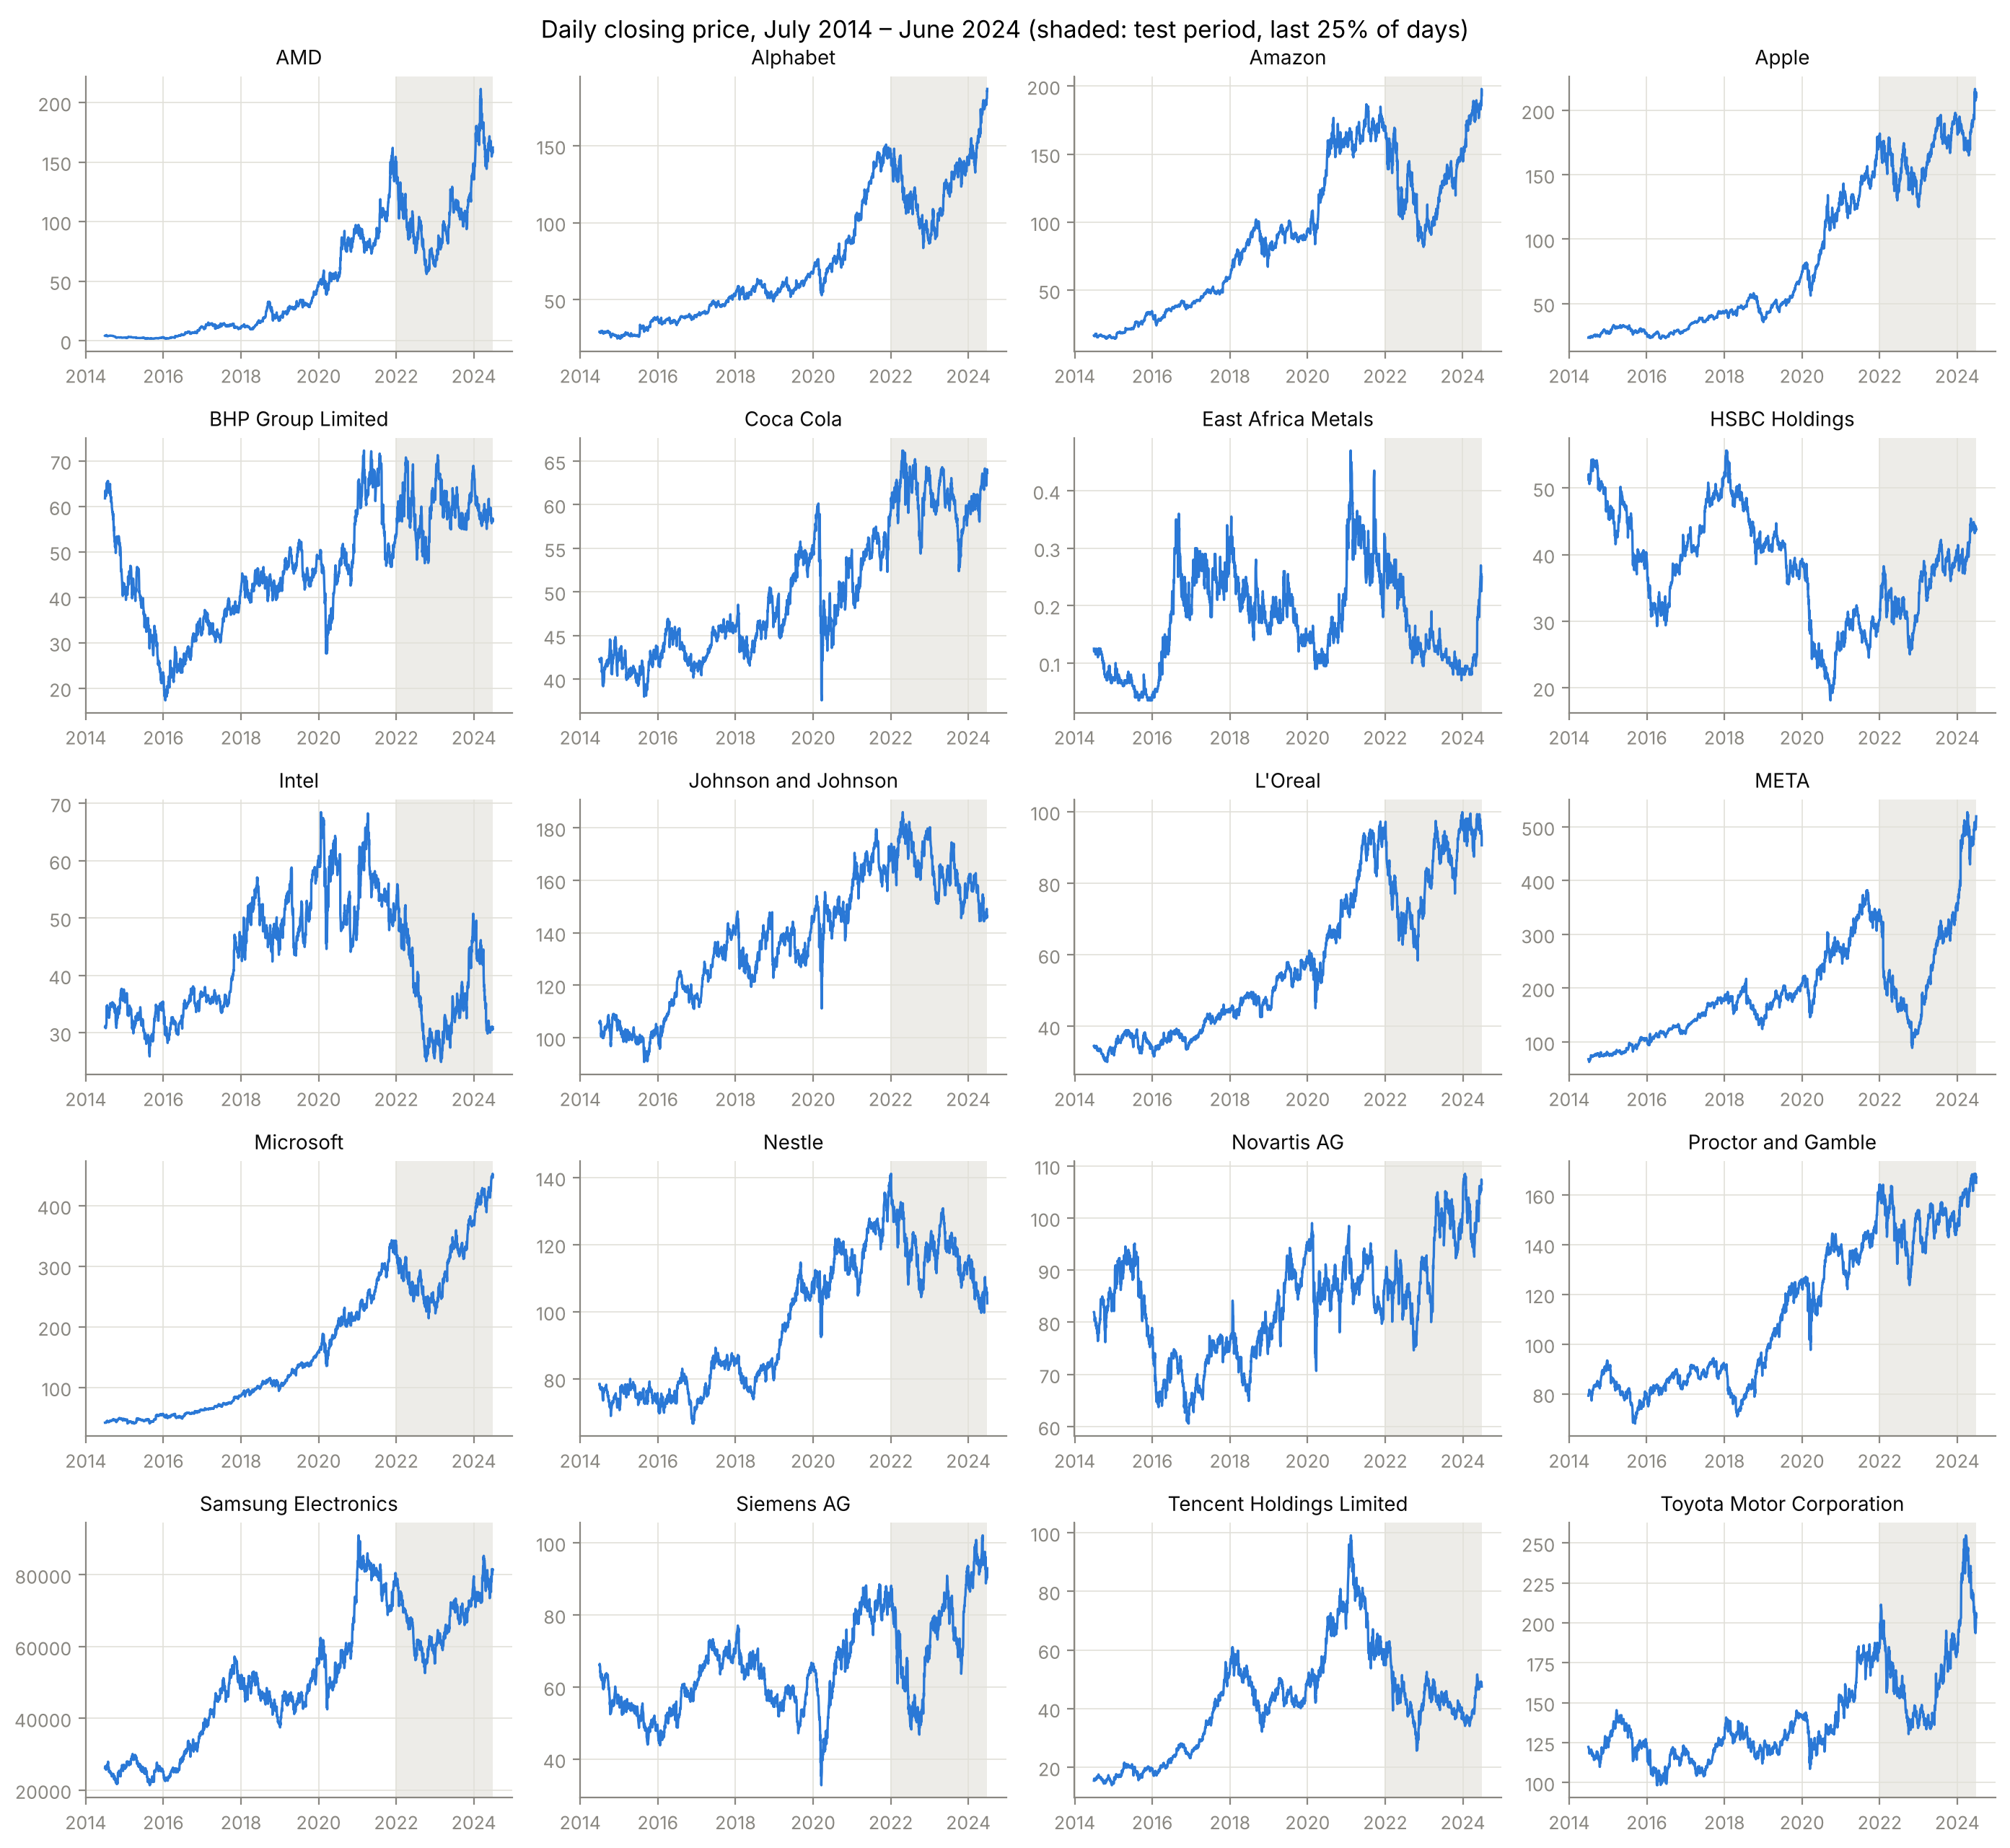

,company,growth over 10 years (%),test days above training max (%)
0,AMD,3743.8,12.1
2,Amazon,1062.8,2.2
12,Microsoft,967.5,27.7
3,Apple,800.9,26.6
11,META,663.4,17.5
1,Alphabet,543.2,11.3
16,Samsung Electronics,211.1,0.0
18,Tencent Holdings Limited,208.0,0.0
10,L'Oreal,163.0,7.6
15,Proctor and Gamble,108.0,10.3


In [2]:
import matplotlib.dates as mdates

# Chart style used throughout the notebook
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
COLORS = {"Actual": INK, "Naive": MUTED, "ARIMA": "#2a78d6", "FNN": "#eb6834"}
plt.rcParams.update({
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 9, "lines.linewidth": 1.2,
})

TRAIN_SHARE = 0.75

fig, axes = plt.subplots(5, 4, figsize=(14, 13))
for ax, (name, df) in zip(axes.flat, data.items()):
    split = int(len(df) * TRAIN_SHARE)
    ax.plot(df["Date"], df["Close"], color=COLORS["ARIMA"])
    ax.axvspan(df["Date"].iloc[split], df["Date"].iloc[-1], color=GRID, alpha=0.6, lw=0)
    ax.set_title(name, fontsize=10, color=INK)
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("Daily closing price, July 2014 – June 2024 (shaded: test period, last 25% of days)", fontsize=12)
fig.tight_layout()
plt.show()

trend = pd.DataFrame([
    {
        "company": name,
        "growth over 10 years (%)": (df["Close"].iloc[-1] / df["Close"].iloc[0] - 1) * 100,
        "test days above training max (%)": (df["Close"].iloc[int(len(df) * TRAIN_SHARE):]
                                              > df["Close"].iloc[:int(len(df) * TRAIN_SHARE)].max()).mean() * 100,
    }
    for name, df in data.items()
]).sort_values("growth over 10 years (%)", ascending=False).round(1)
trend

### Interpretation
- Ten-year growth ranges from −15% (HSBC) to +3,744% (AMD). The test period (2022 to mid-2024) covers both the 2022 market fall and the 2023–24 rally in tech stocks.
- For many companies the test period reaches prices **never seen in training**: Coca-Cola closes above its training maximum on 63% of test days, and Novartis, Microsoft, Toyota and Apple on 27–29%.
- A model trained on price *levels* has to extrapolate beyond anything it learned on those days. So the models below predict **daily returns** (percentage changes), which stay in a similar range across years, and convert them back to prices.

**3. Train/test split and naive baseline**

Splits each company's history **in date order**: the first 75% of days for training and the last 25% for testing, so no model ever sees the future. It then builds the naive forecast (tomorrow's close = today's close) for every test day and scores it with the **mean absolute percentage error (MAPE)**.

In [3]:
def split_series(df, train_share=TRAIN_SHARE):
    """Return closing prices and the index of the first test day."""
    close = df["Close"].to_numpy()
    return close, int(len(close) * train_share)


def mape(pred, actual):
    """Mean absolute percentage error, in %."""
    return np.mean(np.abs(pred - actual) / actual) * 100


def direction_accuracy(pred, actual, prev):
    """% of days the model called the up/down move correctly.
    Days when the price did not move, or the model predicted no change, are skipped."""
    keep = (np.sign(pred - prev) != 0) & (np.sign(actual - prev) != 0)
    return np.mean(np.sign(pred - prev)[keep] == np.sign(actual - prev)[keep]) * 100


forecasts = {}   # forecasts[company] = {"actual": ..., "prev": ..., "Naive": ..., later "ARIMA", "FNN"}
for name, df in data.items():
    close, split = split_series(df)
    forecasts[name] = {
        "dates": df["Date"].iloc[split:].to_numpy(),
        "actual": close[split:],
        "prev": close[split - 1:-1],      # yesterday's close for each test day
    }
    forecasts[name]["Naive"] = forecasts[name]["prev"]

naive_table = pd.DataFrame([
    {"company": name, "train days": int(len(data[name]) * TRAIN_SHARE), "test days": len(f["actual"]),
     "first test day": pd.Timestamp(f["dates"][0]).date(), "naive MAPE (%)": mape(f["Naive"], f["actual"])}
    for name, f in forecasts.items()
]).sort_values("naive MAPE (%)").round(3)
print(f"Average naive MAPE across 20 companies: {naive_table['naive MAPE (%)'].mean():.2f}%")
naive_table

Average naive MAPE across 20 companies: 1.51%


,company,train days,test days,first test day,naive MAPE (%)
5,Coca Cola,1887,629,2021-12-28,0.719
9,Johnson and Johnson,1887,629,2021-12-28,0.758
15,Proctor and Gamble,1887,629,2021-12-28,0.811
14,Novartis AG,1886,629,2021-12-27,0.861
13,Nestle,1886,629,2021-12-27,0.900
16,Samsung Electronics,1842,614,2021-12-27,1.088
19,Toyota Motor Corporation,1886,629,2021-12-27,1.208
7,HSBC Holdings,1886,629,2021-12-27,1.220
10,L'Oreal,1886,629,2021-12-27,1.285
3,Apple,1887,629,2021-12-28,1.305


### Interpretation
- Each company has about 1,880 training days (July 2014 – December 2021) and 629 test days (late December 2021 – June 2024). Samsung has slightly fewer because the Korean market has fewer trading days.
- The naive forecast is already close: on average it is off by **1.51%** a day, ranging from 0.72% (Coca-Cola) to 3.88% (East Africa Metals). Consumer-goods companies move least from day to day; tech stocks and the thinly traded penny stock move most.
- This is the bar to beat. A forecast line that hugs the actual price looks impressive on a chart, but a model is only useful if its error is **lower than the naive forecast's**.

**4. ARIMA**

Fits an ARIMA(p, 1, q) model to each company's **log** closing price on the training days only, trying p and q from 0 to 2 and keeping the order with the lowest AIC. The fitted model then forecasts each test day one step ahead, using actual prices up to the previous day but no refitting. The table compares its MAPE with the naive forecast.

In [4]:
def fit_arima(log_price_train):
    """Grid-search ARIMA(p,1,q) for p, q in 0..2 on the training data; return the fit with the lowest AIC."""
    best = None
    for p in range(3):
        for q in range(3):
            try:
                fit = ARIMA(log_price_train, order=(p, 1, q)).fit()
            except Exception:
                continue
            if best is None or fit.aic < best.aic:
                best = fit
    return best


arima_fits = {}
arima_rows = []
for name, df in data.items():
    close, split = split_series(df)
    log_price = np.log(close)
    fit = fit_arima(log_price[:split])
    arima_fits[name] = fit
    # Extend the fitted model with the test days (parameters stay fixed),
    # then take its one-step-ahead prediction for each test day
    extended = fit.append(log_price[split:], refit=False)
    forecasts[name]["ARIMA"] = np.exp(np.asarray(extended.predict(start=split, end=len(close) - 1)))
    f = forecasts[name]
    arima_rows.append({
        "company": name,
        "order": fit.model.order,
        "ARIMA MAPE (%)": mape(f["ARIMA"], f["actual"]),
        "naive MAPE (%)": mape(f["Naive"], f["actual"]),
    })

arima_table = pd.DataFrame(arima_rows)
arima_table["ARIMA − naive"] = arima_table["ARIMA MAPE (%)"] - arima_table["naive MAPE (%)"]
print(f"ARIMA beats naive for {(arima_table['ARIMA − naive'] < 0).sum()} of 20 companies")
print(f"Average MAPE: ARIMA {arima_table['ARIMA MAPE (%)'].mean():.3f}%, naive {arima_table['naive MAPE (%)'].mean():.3f}%")
arima_table.sort_values("ARIMA − naive").round(3)

ARIMA beats naive for 0 of 20 companies
Average MAPE: ARIMA 1.537%, naive 1.513%


,company,order,ARIMA MAPE (%),naive MAPE (%),ARIMA − naive
2,Amazon,"(0, 1, 0)",1.800,1.800,0.000
18,Tencent Holdings Limited,"(2, 1, 2)",2.057,2.057,0.001
11,META,"(1, 1, 0)",2.058,2.058,0.001
16,Samsung Electronics,"(2, 1, 1)",1.089,1.088,0.001
13,Nestle,"(1, 1, 0)",0.901,0.900,0.001
7,HSBC Holdings,"(2, 1, 0)",1.224,1.220,0.004
14,Novartis AG,"(0, 1, 2)",0.866,0.861,0.005
5,Coca Cola,"(1, 1, 2)",0.725,0.719,0.006
0,AMD,"(1, 1, 2)",2.519,2.513,0.007
15,Proctor and Gamble,"(2, 1, 2)",0.819,0.811,0.008


### Interpretation
- For Amazon, the best order is ARIMA(0, 1, 0), a pure random walk, which makes exactly the same forecast as the naive model (identical error).
- For the other 19 companies, ARIMA is slightly **worse** than naive: by 0.001–0.06 percentage points for 18 of them, and by 0.26 points for East Africa Metals. Average MAPE is 1.537% against 1.513% for naive.
- The small patterns ARIMA finds in 2014–2021 prices do not carry over to 2022–2024. A lower AIC on the training data does not mean better forecasts, which is consistent with daily stock prices behaving close to a random walk.

**5. Neural network**

Trains a feed-forward neural network (one hidden layer of 40 nodes, Adam optimiser, as in the original project) for each company. Its inputs are the **previous 10 daily log returns** and its output is the next day's return, which is converted back to a price. The input scaler is fitted on training days only, and training stops early when the error on a held-out 10% of training days stops improving.

In [5]:
LAGS = 10


def lagged_returns(close, lags=LAGS):
    """X[i] = the `lags` log returns before day t, y[i] = log return on day t, day[i] = t."""
    r = np.diff(np.log(close))                 # r[k] = return from day k to day k+1
    X = np.array([r[k - lags:k] for k in range(lags, len(r))])
    y = r[lags:]
    day = np.arange(lags, len(r)) + 1          # index of the day whose close is predicted
    return X, y, day


fnn_models = {}
fnn_rows = []
for name, df in data.items():
    close, split = split_series(df)
    X, y, day = lagged_returns(close)
    train, test = day < split, day >= split
    scaler = StandardScaler().fit(X[train])
    y_scale = y[train].std()
    model = MLPRegressor(hidden_layer_sizes=(40,), solver="adam", max_iter=1000,
                         early_stopping=True, alpha=1e-3, random_state=0)
    model.fit(scaler.transform(X[train]), y[train] / y_scale)
    predicted_return = model.predict(scaler.transform(X[test])) * y_scale
    forecasts[name]["FNN"] = close[day[test] - 1] * np.exp(predicted_return)
    fnn_models[name] = (model, scaler, y_scale)
    f = forecasts[name]
    fnn_rows.append({
        "company": name,
        "epochs": model.n_iter_,
        "FNN MAPE (%)": mape(f["FNN"], f["actual"]),
        "naive MAPE (%)": mape(f["Naive"], f["actual"]),
    })

fnn_table = pd.DataFrame(fnn_rows)
fnn_table["FNN − naive"] = fnn_table["FNN MAPE (%)"] - fnn_table["naive MAPE (%)"]
print(f"FNN beats naive for {(fnn_table['FNN − naive'] < 0).sum()} of 20 companies")
print(f"Average MAPE: FNN {fnn_table['FNN MAPE (%)'].mean():.3f}%, naive {fnn_table['naive MAPE (%)'].mean():.3f}%")
fnn_table.sort_values("FNN − naive").round(3)

FNN beats naive for 0 of 20 companies
Average MAPE: FNN 1.592%, naive 1.513%


,company,epochs,FNN MAPE (%),naive MAPE (%),FNN − naive
5,Coca Cola,34,0.738,0.719,0.020
14,Novartis AG,57,0.886,0.861,0.025
13,Nestle,44,0.925,0.900,0.025
18,Tencent Holdings Limited,47,2.083,2.057,0.026
15,Proctor and Gamble,117,0.842,0.811,0.031
16,Samsung Electronics,40,1.123,1.088,0.036
3,Apple,26,1.343,1.305,0.038
9,Johnson and Johnson,18,0.803,0.758,0.045
7,HSBC Holdings,31,1.266,1.220,0.046
4,BHP Group Limited,43,1.602,1.555,0.047


### Interpretation
- The neural network is worse than naive for **all 20 companies**, by 0.02–0.11 percentage points for most and 0.22–0.43 for Intel and East Africa Metals. Average MAPE is 1.592% against 1.513% for naive.
- Early stopping ended training after 17–117 epochs: the error on held-out training days stopped improving quickly because there is little stable pattern in past returns to learn.
- Its predicted returns are small adjustments around zero, so its forecasts stay close to yesterday's price, and those adjustments add error rather than remove it.

**6. Model comparison**

Puts the three models side by side for every company: MAPE, and for ARIMA and the neural network, the share of days they called the price direction (up or down) correctly. The first chart shows how much worse or better each model is than naive; the second zooms in on the last 60 test days for one company to show what the forecasts look like.

Averages across 20 companies:
Naive MAPE              1.513
ARIMA MAPE              1.537
FNN MAPE                1.592
ARIMA direction (%)    50.112
FNN direction (%)      50.821


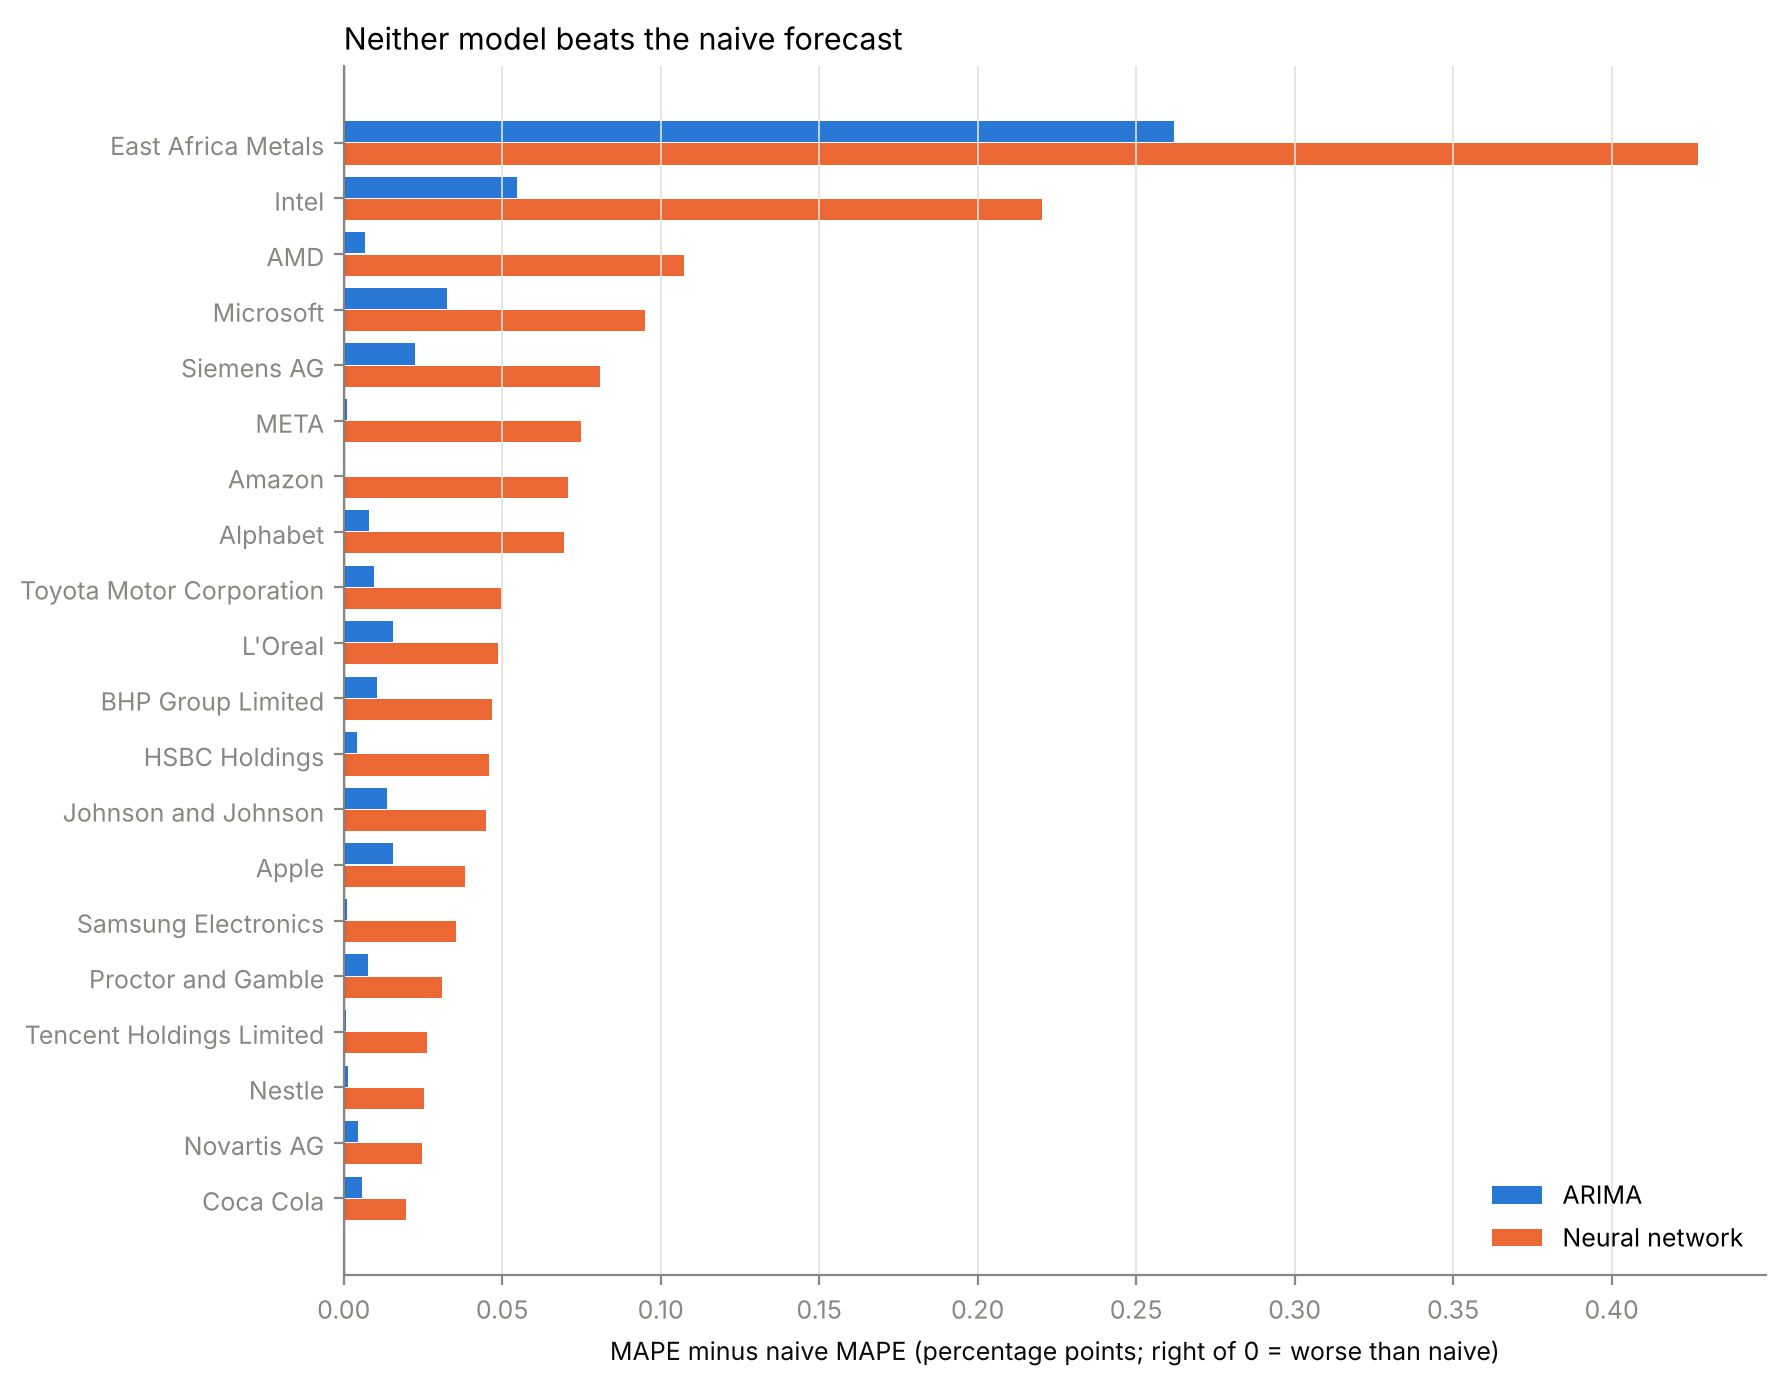

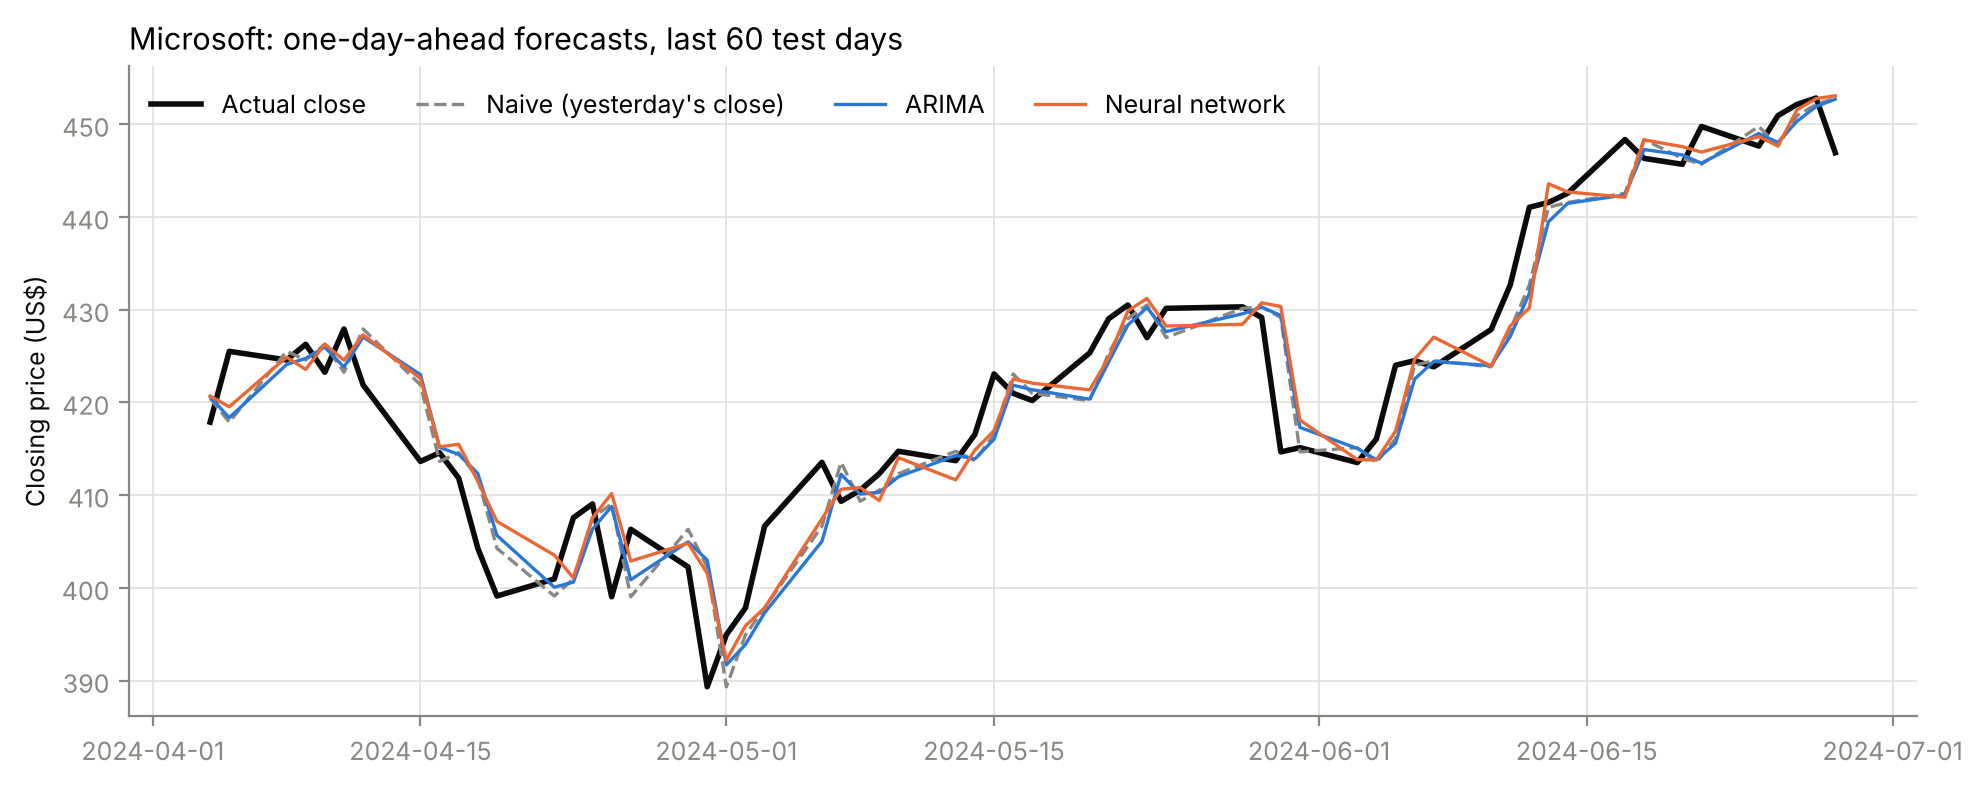

,Naive MAPE,ARIMA MAPE,FNN MAPE,ARIMA direction (%),FNN direction (%)
company,,,,,
AMD,2.513,2.519,2.620,51.597,48.243
Alphabet,1.548,1.556,1.617,48.967,48.808
Amazon,1.800,1.800,1.871,50.405,49.042
Apple,1.305,1.320,1.343,48.485,51.515
BHP Group Limited,1.555,1.566,1.602,50.000,49.679
Coca Cola,0.719,0.725,0.738,49.839,50.643
East Africa Metals,3.881,4.143,4.309,58.576,60.841
HSBC Holdings,1.220,1.224,1.266,50.241,49.599
Intel,1.801,1.855,2.021,48.083,48.083


In [6]:
comparison = pd.DataFrame([
    {
        "company": name,
        "Naive MAPE": mape(f["Naive"], f["actual"]),
        "ARIMA MAPE": mape(f["ARIMA"], f["actual"]),
        "FNN MAPE": mape(f["FNN"], f["actual"]),
        "ARIMA direction (%)": direction_accuracy(f["ARIMA"], f["actual"], f["prev"]),
        "FNN direction (%)": direction_accuracy(f["FNN"], f["actual"], f["prev"]),
    }
    for name, f in forecasts.items()
]).set_index("company")
print("Averages across 20 companies:")
print(comparison.mean().round(3).to_string())

# Chart 1: difference from naive (positive = worse than naive)
diff = pd.DataFrame({
    "ARIMA": comparison["ARIMA MAPE"] - comparison["Naive MAPE"],
    "FNN": comparison["FNN MAPE"] - comparison["Naive MAPE"],
}).sort_values("FNN")
fig, ax = plt.subplots(figsize=(9, 7))
ypos = np.arange(len(diff))
ax.barh(ypos + 0.2, diff["ARIMA"], height=0.38, color=COLORS["ARIMA"], label="ARIMA")
ax.barh(ypos - 0.2, diff["FNN"], height=0.38, color=COLORS["FNN"], label="Neural network")
ax.axvline(0, color=INK, lw=0.8)
ax.set_yticks(ypos, diff.index)
ax.set_xlabel("MAPE minus naive MAPE (percentage points; right of 0 = worse than naive)")
ax.set_title("Neither model beats the naive forecast", loc="left", fontsize=11)
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

# Chart 2: last 60 test days for one company
company = "Microsoft"
f = forecasts[company]
last = slice(-60, None)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(f["dates"][last], f["actual"][last], color=COLORS["Actual"], lw=2, label="Actual close")
ax.plot(f["dates"][last], f["Naive"][last], color=COLORS["Naive"], ls="--", label="Naive (yesterday's close)")
ax.plot(f["dates"][last], f["ARIMA"][last], color=COLORS["ARIMA"], label="ARIMA")
ax.plot(f["dates"][last], f["FNN"][last], color=COLORS["FNN"], label="Neural network")
ax.set_title(f"{company}: one-day-ahead forecasts, last 60 test days", loc="left", fontsize=11)
ax.set_ylabel("Closing price (US$)")
ax.legend(frameon=False, ncol=4, loc="upper left")
fig.tight_layout()
plt.show()

comparison.round(3)

### Interpretation
- Averaged over 20 companies, naive is the most accurate (1.513%), then ARIMA (1.537%), then the neural network (1.592%). The bar chart shows the same order for almost every company.
- Both models call the up/down direction correctly on about **50%** of days, the same as a coin flip. The exception is East Africa Metals (59–61%): its thin trading means a rise is often followed by a fall, a pattern both models pick up, but they still misjudge the size of the moves.
- The Microsoft chart shows why the forecasts look good at a glance: every line is essentially the actual price shifted one day to the right. The models mostly repeat yesterday's close.

**7. Why the original results looked so good**

Reproduces the setup of the original MATLAB script (`original_matlab/neural.m`) for all 20 companies: the inputs are **the same day's** Open, High, Low, Close and Volume, everything is z-score scaled using the **whole** dataset, and the network predicts that same day's Close. A second version removes Close from the inputs but keeps the same day's Open, High and Low.

In [7]:
def original_setup(df, drop_close=False):
    """Same-day inputs -> same-day Close, scaled on the full dataset (as in neural.m)."""
    cols = ["Open", "High", "Low", "Volume"] if drop_close else ["Open", "High", "Low", "Close", "Volume"]
    X = df[cols].to_numpy(dtype=float)
    y = df["Close"].to_numpy(dtype=float)
    X = (X - X.mean(axis=0)) / X.std(axis=0)          # scaled with test-period data included
    y_mean, y_std = y.mean(), y.std()
    split = int(len(y) * TRAIN_SHARE)
    model = MLPRegressor(hidden_layer_sizes=(40,), max_iter=1000, random_state=0)
    model.fit(X[:split], (y[:split] - y_mean) / y_std)
    pred = model.predict(X[split:]) * y_std + y_mean
    return mape(pred, y[split:])


leak_table = pd.DataFrame([
    {
        "company": name,
        "original setup MAPE (%)": original_setup(df),
        "without Close, still same-day (%)": original_setup(df, drop_close=True),
        "naive MAPE (%)": comparison.loc[name, "Naive MAPE"],
    }
    for name, df in data.items()
]).set_index("company")
print("Averages across 20 companies:")
print(leak_table.mean().round(3).to_string())
leak_table.round(3)

Averages across 20 companies:
original setup MAPE (%)              0.914
without Close, still same-day (%)    1.719
naive MAPE (%)                       1.513


,original setup MAPE (%),"without Close, still same-day (%)",naive MAPE (%)
company,,,
AMD,1.535,3.193,2.513
Alphabet,1.103,2.029,1.548
Amazon,1.592,2.356,1.800
Apple,0.778,2.875,1.305
BHP Group Limited,0.687,0.980,1.555
Coca Cola,0.627,1.950,0.719
East Africa Metals,1.435,2.491,3.881
HSBC Holdings,0.633,0.855,1.220
Intel,1.098,1.428,1.801


### Interpretation
- With the original setup, the network's average error drops to **0.91%**, well below naive (1.51%), and it "beats" naive for 19 of 20 companies. This is not forecasting: the inputs already contain that day's closing price, which is the answer.
- Removing Close but keeping the same day's Open, High and Low still uses information from the day being predicted. The error rises to 1.72%, now worse than naive, partly because the test-period prices are higher than anything the network trained on.
- To forecast tomorrow, a model can only use what is known today. That is why the original results looked so strong, and why the fair versions in steps 4–5 do not beat naive.

**8. Out-of-sample check: July 2024**

First checks that each `validation/` file continues the same price series as its training file. It then applies the models already fitted above, without retraining, to the 19–20 trading days of July 2024, again forecasting each day from the previous day's information only.

In [8]:
# Check that each validation file continues the same price series
jumps = pd.Series({
    name: validation[name.lower()]["Close"].iloc[0] / df["Close"].iloc[-1] - 1
    for name, df in data.items()
})
mismatched = jumps[jumps.abs() > 0.20]
print("Validation files that do not continue the training series (first-day jump > 20%):")
print((mismatched * 100).round(1).astype(str).add("%").to_string(), "\n")

val_rows = []
for name, df in data.items():
    if name in mismatched.index:
        continue
    val = validation[name.lower()]
    full_close = np.concatenate([df["Close"].to_numpy(), val["Close"].to_numpy()])
    start = len(df)                                   # first validation day
    actual, prev = full_close[start:], full_close[start - 1:-1]

    extended = arima_fits[name].append(np.log(full_close[split_series(df)[1]:]), refit=False)
    arima_pred = np.exp(np.asarray(extended.predict(start=start, end=len(full_close) - 1)))

    model, scaler, y_scale = fnn_models[name]
    X, _, day = lagged_returns(full_close)
    keep = day >= start
    fnn_pred = full_close[day[keep] - 1] * np.exp(model.predict(scaler.transform(X[keep])) * y_scale)

    val_rows.append({
        "company": name,
        "days": len(actual),
        "Naive MAPE": mape(prev, actual),
        "ARIMA MAPE": mape(arima_pred, actual),
        "FNN MAPE": mape(fnn_pred, actual),
    })

val_table = pd.DataFrame(val_rows).set_index("company")
print(f"Averages across {len(val_table)} companies (July 2024):")
print(val_table.drop(columns="days").mean().round(3).to_string())
print(f"\nARIMA beats naive for {(val_table['ARIMA MAPE'] < val_table['Naive MAPE']).sum()} companies, "
      f"FNN for {(val_table['FNN MAPE'] < val_table['Naive MAPE']).sum()}")
val_table.round(3)

Validation files that do not continue the training series (first-day jump > 20%):
L'Oreal       355.0%
Siemens AG    -74.0% 



Averages across 18 companies (July 2024):
Naive MAPE    1.458
ARIMA MAPE    1.468
FNN MAPE      1.502

ARIMA beats naive for 7 companies, FNN for 5


,days,Naive MAPE,ARIMA MAPE,FNN MAPE
company,,,,
AMD,19,2.972,2.954,3.046
Alphabet,19,1.423,1.466,1.689
Amazon,19,1.212,1.212,1.272
Apple,19,1.290,1.313,1.464
BHP Group Limited,19,1.058,1.074,1.063
Coca Cola,19,0.669,0.662,0.630
East Africa Metals,19,3.820,3.899,3.703
HSBC Holdings,19,0.657,0.663,0.675
Intel,19,1.907,1.895,1.839


### Interpretation
- The validation files for **Siemens** and **L'Oreal** are a different listing from their training files (their price jumps by −74% and +355% overnight), so those two companies are excluded. Results that use them as a continuation of the training series are not valid.
- For the other 18 companies, July 2024 confirms the test results: naive 1.458%, ARIMA 1.468%, neural network 1.502%.
- ARIMA beats naive for 7 companies and the neural network for 5, but over only 19–20 days these wins are within normal day-to-day variation.

**9. Conclusion**

- **Neither model beats the naive forecast.** One day ahead, "tomorrow = today" was the most accurate on test data (1.51% average error), ahead of ARIMA (1.54%) and the neural network (1.59%), and both models called the direction of moves about as often as a coin flip.
- **The original project's strong results came from information leakage**: the network was given the same day's closing price and the same day's high, low and open. Removing that leakage removes the apparent advantage.
- **This matches what is known about stock prices**: daily changes are close to unpredictable from past prices alone, so a model that reports much better than naive accuracy should first be checked for leakage.
- **Two validation files are mismatched** (Siemens, L'Oreal) and should be replaced with the same listing as the training data.

**Possible next steps:** forecast over longer horizons (weekly or monthly), add information beyond past prices (trading volume, market index, news sentiment), and test whether any model's edge over naive is statistically significant (Diebold–Mariano test).